In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("superstore.csv", encoding="latin-1")
print(df.shape)
print(df.columns.tolist())
df.head()


(9994, 21)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [2]:
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicate rows:", df.drop(columns=["Row ID"]).duplicated().sum())

df = df.drop_duplicates(subset=[c for c in df.columns if c != "Row ID"])
df = df.dropna(subset=["Sales", "Profit"])
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y", errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y", errors="coerce")
print("Bad dates:", df["Order Date"].isnull().sum())
print("Rows after cleaning:", len(df))


Missing values:
 Series([], dtype: int64)
Duplicate rows: 1
Bad dates: 0
Rows after cleaning: 9993


In [3]:
print("From", df["Order Date"].min().date(), "to", df["Order Date"].max().date())

cat = df.groupby("Category")[["Sales", "Profit"]].sum()
cat["Sales %"] = (cat["Sales"] / cat["Sales"].sum() * 100).round(1)
cat["Profit %"] = (cat["Profit"] / cat["Profit"].sum() * 100).round(1)
cat["Margin %"] = (cat["Profit"] / cat["Sales"] * 100).round(1)
print(cat, "\n")

reg = df.groupby("Region")[["Sales", "Profit"]].sum()
reg["Margin %"] = (reg["Profit"] / reg["Sales"] * 100).round(1)
print(reg.sort_values("Profit", ascending=False), "\n")

print("Most loss-making sub-categories:")
print(df.groupby("Sub-Category")["Profit"].sum().sort_values().head(3), "\n")

print("Average profit by discount level:")
print(df.groupby(pd.cut(df["Discount"], [-0.01, 0, 0.2, 0.4, 1]))["Profit"].mean().round(1))

From 2014-01-03 to 2017-12-30
                       Sales       Profit  Sales %  Profit %  Margin %
Category                                                              
Furniture        741718.4233   18463.3316     32.3       6.4       2.5
Office Supplies  719047.0320  122490.8008     31.3      42.8      17.0
Technology       836154.0330  145454.9481     36.4      50.8      17.4 

               Sales       Profit  Margin %
Region                                     
West     725457.8245  108418.4489      14.9
East     678499.8680   91534.8388      13.5
South    391721.9050   46749.4303      11.9
Central  501239.8908   39706.3625       7.9 

Most loss-making sub-categories:
Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Name: Profit, dtype: float64 

Average profit by discount level:
Discount
(-0.01, 0.0]     66.9
(0.0, 0.2]       26.5
(0.2, 0.4]      -78.0
(0.4, 1.0]     -106.7
Name: Profit, dtype: float64


/tmp/ipykernel_2518/1078797280.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby(pd.cut(df["Discount"], [-0.01, 0, 0.2, 0.4, 1]))["Profit"].mean().round(1))


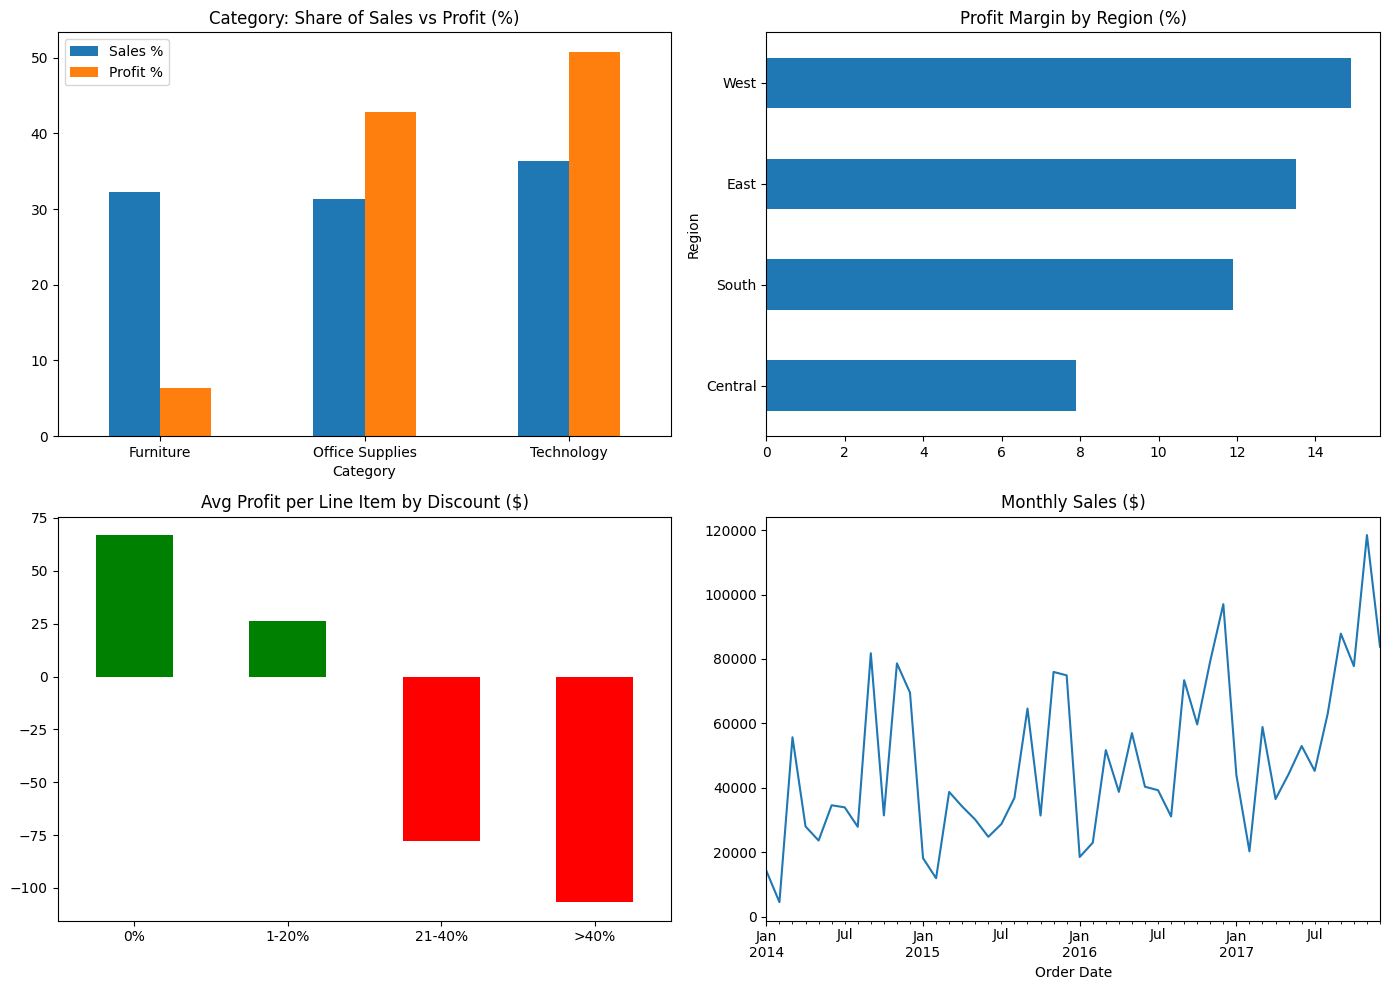

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cat[["Sales %", "Profit %"]].plot(kind="bar", ax=axes[0, 0], title="Category: Share of Sales vs Profit (%)", rot=0)
reg["Margin %"].sort_values().plot(kind="barh", ax=axes[0, 1], title="Profit Margin by Region (%)")

disc = df.groupby(pd.cut(df["Discount"], [-0.01, 0, 0.2, 0.4, 1]), observed=True)["Profit"].mean()
disc.index = ["0%", "1-20%", "21-40%", ">40%"]
disc.plot(kind="bar", ax=axes[1, 0], title="Avg Profit per Line Item by Discount ($)", rot=0,
          color=["green" if v > 0 else "red" for v in disc])

df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum().plot(ax=axes[1, 1], title="Monthly Sales ($)")

plt.tight_layout()
plt.savefig("retail_charts.png", dpi=150)
plt.show()


In [5]:
from google.colab import files
files.download("retail_charts.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
yearly = df.groupby(df["Order Date"].dt.year)["Sales"].sum()
print(yearly.round(0))
print("Growth 2014 to 2017:", round((yearly[2017] / yearly[2014] - 1) * 100, 1), "%")

q4 = df[df["Order Date"].dt.month.isin([9, 10, 11, 12])]["Sales"].sum()
print("Share of sales in Sep-Dec:", round(q4 / df["Sales"].sum() * 100, 1), "%")

Order Date
2014    483966.0
2015    470533.0
2016    609206.0
2017    733215.0
Name: Sales, dtype: float64
Growth 2014 to 2017: 51.5 %
Share of sales in Sep-Dec: 51.6 %
